In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [3]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


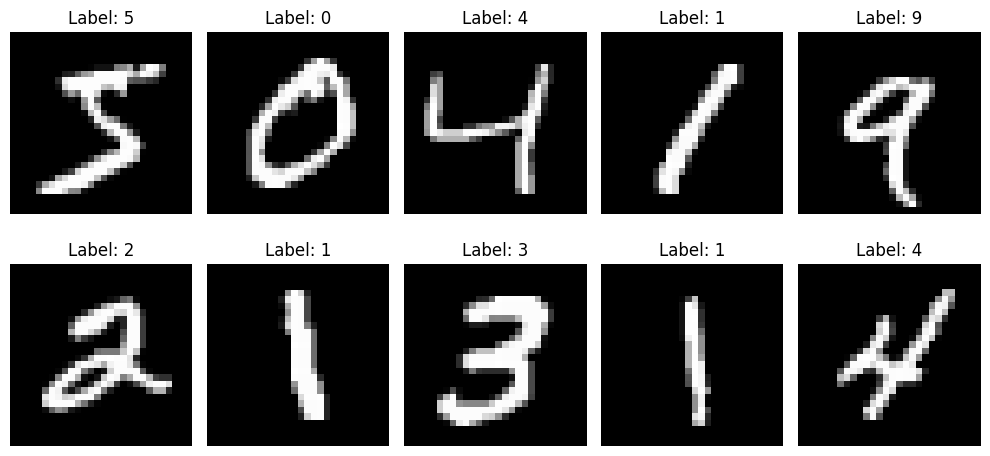

In [4]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [7]:
# Normalize pixel values
x_train = x_train / 255.0
x_test = x_test / 255.0

# Reshape images to include the channel dimension
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)


In [5]:
model = Sequential([
    # First convolutional layer
    Conv2D(32, (3, 3), activation='relu',
           input_shape=(28, 28, 1)),

    # First pooling layer
    MaxPooling2D((2, 2)),

    # Second convolutional layer
    Conv2D(64, (3, 3), activation='relu'),

    # Second pooling layer
    MaxPooling2D((2, 2)),

    # Convert feature maps into a vector
    Flatten(),

    # Fully connected layer
    Dense(64, activation='relu'),

    # Prevent overfitting
    Dropout(0.3),

    # Output layer: 10 digits
    Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [7]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.9133 - loss: 0.2809 - val_accuracy: 0.9855 - val_loss: 0.0539
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9726 - loss: 0.0926 - val_accuracy: 0.9880 - val_loss: 0.0407
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9788 - loss: 0.0689 - val_accuracy: 0.9892 - val_loss: 0.0410
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9826 - loss: 0.0568 - val_accuracy: 0.9905 - val_loss: 0.0366
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9856 - loss: 0.0480 - val_accuracy: 0.9910 - val_loss: 0.0313


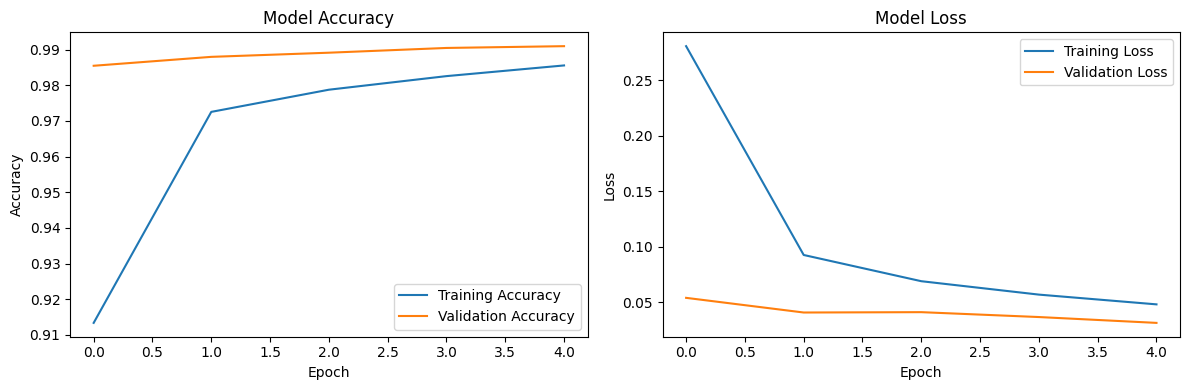

In [8]:
plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9904 - loss: 0.0289
Test Accuracy: 99.04000163078308 %
Test Loss: 0.028871173039078712


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


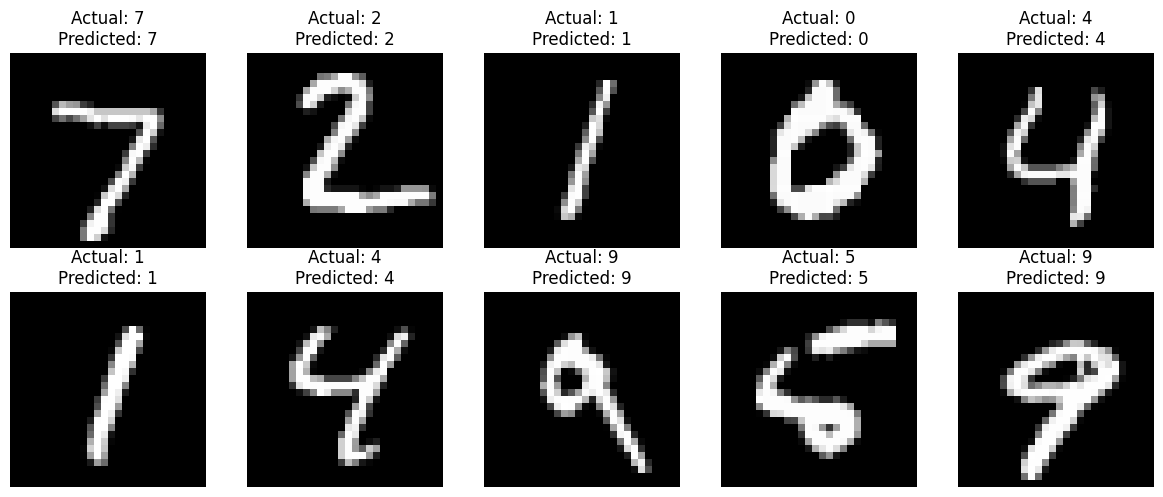

In [10]:
predictions = model.predict(x_test)

# Get the digit with the highest probability
predicted_labels = np.argmax(predictions, axis=1)

# Display first 10 predictions
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {predicted_labels[i]}"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

In [12]:
from sklearn.metrics import classification_report

print(classification_report(y_test, predicted_labels))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.98      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.99      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       0.98      0.99      0.98      1028
           8       1.00      0.99      0.99       974
           9       1.00      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [13]:
model.save("handwritten_digit_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [15]:
import os

print(os.listdir('/content'))

['.config', 'digit2.png', 'handwritten_digit_cnn.keras', '.ipynb_checkpoints', 'digit1.png', 'sample_data']


1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


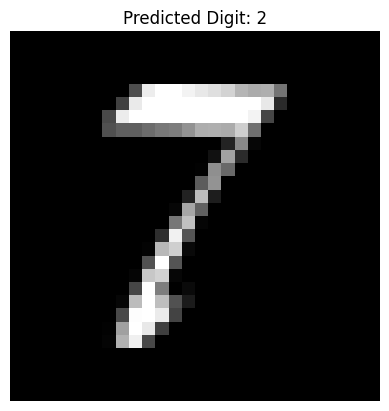

Predicted digit: 2
Confidence: 63.99 %


In [16]:
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt

# Open uploaded image
img = Image.open("/content/digit1.png").convert("L")

# Make sure background is black and digit is white
if np.array(img).mean() > 127:
    img = ImageOps.invert(img)

# Crop around the digit
img = img.point(lambda p: 255 if p > 50 else 0)
bbox = img.getbbox()
img = img.crop(bbox)

# Resize while maintaining aspect ratio
img.thumbnail((20, 20))

# Place digit in the centre of a 28x28 black image
canvas = Image.new("L", (28, 28), 0)
canvas.paste(img, ((28-img.width)//2, (28-img.height)//2))

# Normalize and reshape
input_img = np.array(canvas) / 255.0
input_img = input_img.reshape(1, 28, 28, 1)

# Predict
prediction = model.predict(input_img)
predicted_digit = np.argmax(prediction)

plt.imshow(canvas, cmap="gray")
plt.title(f"Predicted Digit: {predicted_digit}")
plt.axis("off")
plt.show()

print("Predicted digit:", predicted_digit)
print("Confidence:", round(np.max(prediction) * 100, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


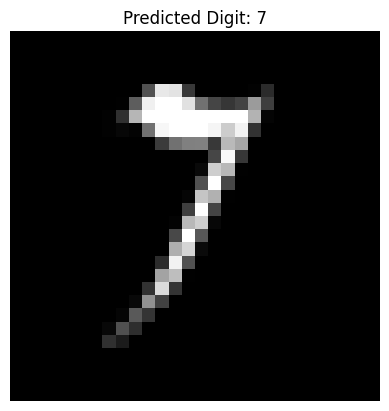

Predicted digit: 7
Confidence: 98.02 %


In [17]:
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt

# Open uploaded image
img = Image.open("/content/digit2.png").convert("L")

# Make sure background is black and digit is white
if np.array(img).mean() > 127:
    img = ImageOps.invert(img)

# Crop around the digit
img = img.point(lambda p: 255 if p > 50 else 0)
bbox = img.getbbox()
img = img.crop(bbox)

# Resize while maintaining aspect ratio
img.thumbnail((20, 20))

# Place digit in the centre of a 28x28 black image
canvas = Image.new("L", (28, 28), 0)
canvas.paste(img, ((28-img.width)//2, (28-img.height)//2))

# Normalize and reshape
input_img = np.array(canvas) / 255.0
input_img = input_img.reshape(1, 28, 28, 1)

# Predict
prediction = model.predict(input_img)
predicted_digit = np.argmax(prediction)

plt.imshow(canvas, cmap="gray")
plt.title(f"Predicted Digit: {predicted_digit}")
plt.axis("off")
plt.show()

print("Predicted digit:", predicted_digit)
print("Confidence:", round(np.max(prediction) * 100, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step


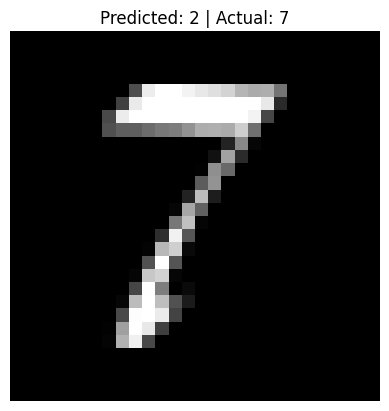

Top 3 predictions:
2 63.99 %
7 33.97 %
3 1.17 %


In [19]:
img = Image.open("/content/digit1.png").convert("L")

if np.array(img).mean() > 127:
    img = ImageOps.invert(img)

img = img.point(lambda p: 255 if p > 50 else 0)
bbox = img.getbbox()
img = img.crop(bbox)

img.thumbnail((20, 20))

canvas_wrong = Image.new("L", (28, 28), 0)
canvas_wrong.paste(
    img,
    ((28-img.width)//2, (28-img.height)//2)
)

input_wrong = np.array(canvas_wrong) / 255.0
input_wrong = input_wrong.reshape(1, 28, 28, 1)

prediction_wrong = model.predict(input_wrong)
predicted_wrong = np.argmax(prediction_wrong)

plt.imshow(canvas_wrong, cmap="gray")
plt.title(f"Predicted: {predicted_wrong} | Actual: 7")
plt.axis("off")
plt.show()

print("Top 3 predictions:")
for digit in np.argsort(prediction_wrong[0])[-3:][::-1]:
    print(digit, round(prediction_wrong[0][digit] * 100, 2), "%")